# Q1 - Dataset description and EDA

**Dataset:** MARCO (MAchine Recognition of Crystallization Outcomes), University at Buffalo
Center for Computational Research - https://marco.ccr.buffalo.edu

**Licence:** CC BY 4.0.

**What we actually have:** 15 TFRecord shards downloaded via `scripts/download_extract.py`
(14,367 images), split once via `scripts/make_splits.py` into `data/splits.csv`
(train/val/test, grouped by drop to avoid leakage - see the Leakage checks section below).

**Task:** 4-class image classification - Clear, Crystals, Precipitate, Other. Crystals is the
decision-relevant minority class.

**Test isolation (CLAUDE.md rule 2):** the test split is read only by `scripts/final_eval.py`.
Everything in this notebook below the split-size table uses train+val only - test images are
never opened and no statistic here is computed from test.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Fixed class order and colour, used in every chart below (never cycled per-chart).
CLASS_ORDER = ["Clear", "Crystals", "Other", "Precipitate"]
CLASS_COLORS = {
    "Clear": "#0072B2",
    "Crystals": "#D55E00",
    "Precipitate": "#E69F00",
    "Other": "#999999",
}

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100

In [2]:
splits = pd.read_csv(DATA_DIR / "splits.csv")
print(splits["split"].value_counts())

# Everything below this point uses train+val only - test is excluded (rule 2).
analysis_df = splits[splits["split"] != "test"].copy()
n_test = (splits["split"] == "test").sum()
print(f"\nEDA uses {len(analysis_df)} train+val images; {n_test} test images are excluded.") 

split
train    10261
val       2053
test      2053
Name: count, dtype: int64

EDA uses 12314 train+val images; 2053 test images are excluded.


In [3]:
splits.head()

,image_id,filename,path,label,source,group_key,split
0,396612,X0000039760279200409281034.png,raw/Clear/X0000039760279200409281034.png,Clear,2,X000003976_w0279,train
1,286612,folderID125_plateID3125_batchID18048_wellNum22...,raw/Precipitate/folderID125_plateID3125_batchI...,Precipitate,3,plate3125well22,train
2,421709,X0000042171126200411151543.png,raw/Precipitate/X0000042171126200411151543.png,Precipitate,2,X000004217_w1126,train
3,90089,folderID281_plateID1281_batchID4174_wellNum16_...,raw/Clear/folderID281_plateID1281_batchID4174_...,Clear,3,plate1281well16,train
4,296118,folderID511_plateID3511_batchID20741_wellNum58...,raw/Precipitate/folderID511_plateID3511_batchI...,Precipitate,3,plate3511well58,train


## Class distribution (train + val)

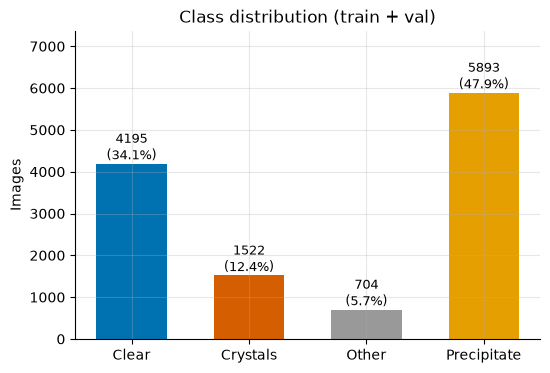

label
Clear          4195
Crystals       1522
Other           704
Precipitate    5893
Name: count, dtype: int64

In [4]:
class_counts = analysis_df["label"].value_counts().reindex(CLASS_ORDER)
class_pct = class_counts / class_counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(CLASS_ORDER, class_counts.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER], width=0.6)
for bar, count, pct in zip(bars, class_counts.values, class_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{count}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Images")
ax.set_title("Class distribution (train + val)")
ax.set_ylim(0, class_counts.max() * 1.25)
fig.savefig(FIGURES_DIR / "q1_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

class_counts

**Is this 15-shard sample representative of the full dataset?** A chi-square goodness-of-fit
test against the published MARCO train-split label distribution (all 407 shards, 415,775
images - see `notebooks/00_download_explore.ipynb`'s last cell), not just an eyeballed
comparison of percentages.

In [5]:
from scipy.stats import chisquare

# Published MARCO train-split label distribution, all 407 shards, n=415,775 - see
# notebooks/00_download_explore.ipynb's last cell. Hardcoded (not recomputed) since
# reproducing it would mean downloading the full ~55GB dataset.
full_population = pd.Series({
    "Clear": 139865,
    "Crystals": 53044,
    "Other": 23299,
    "Precipitate": 199567,
})
expected_props = full_population[CLASS_ORDER] / full_population.sum()
expected_counts = expected_props * class_counts.sum()

chi2_stat, p_value = chisquare(f_obs=class_counts[CLASS_ORDER].values, f_exp=expected_counts.values)

print(f"observed (this sample, train+val, n={class_counts.sum()}):")
print(class_counts[CLASS_ORDER])
print(f"\nexpected (full-population proportions, scaled to n={class_counts.sum()}):")
print(expected_counts.round(1))
print(f"\nchi-square statistic = {chi2_stat:.3f}, df = {len(CLASS_ORDER) - 1}, p-value = {p_value:.4f}")

observed (this sample, train+val, n=12314):
label
Clear          4195
Crystals       1522
Other           704
Precipitate    5893
Name: count, dtype: int64

expected (full-population proportions, scaled to n=12314):
Clear          4142.4
Crystals       1571.0
Other           690.0
Precipitate    5910.6
dtype: float64

chi-square statistic = 2.531, df = 3, p-value = 0.4696


**Reading this:** chi-square = 2.531, df = 3, p = 0.470 - nowhere near the p < 0.05 threshold
needed to reject the null hypothesis that this sample's label distribution matches the full
407-shard population. In other words, the small differences visible above (e.g. 12.4% vs. 12.8%
Crystals) are consistent with ordinary sampling noise from evenly-spaced shard selection, not
evidence of a biased or unrepresentative sample. This backs up the "representative" claim in
`docs/report.md` with an actual test, not just an eyeballed percentage comparison.

## Source institution distribution (train + val)

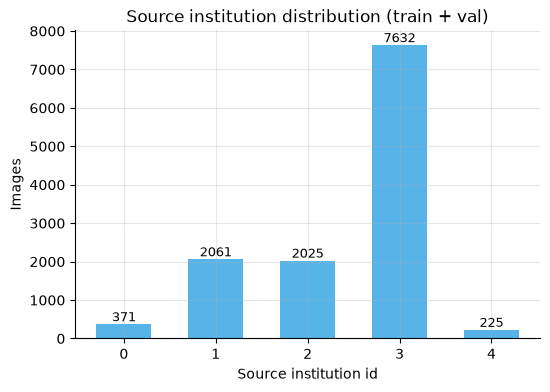

source
0     371
1    2061
2    2025
3    7632
4     225
Name: count, dtype: int64

In [6]:
source_counts = analysis_df["source"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(source_counts.index.astype(str), source_counts.values, color="#56B4E9", width=0.6)
for i, count in enumerate(source_counts.values):
    ax.text(i, count, str(count), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Source institution id")
ax.set_ylabel("Images")
ax.set_title("Source institution distribution (train + val)")
fig.savefig(FIGURES_DIR / "q1_source_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

source_counts

## Class composition by source institution

Does the class mix differ depending on which institution imaged the plate?

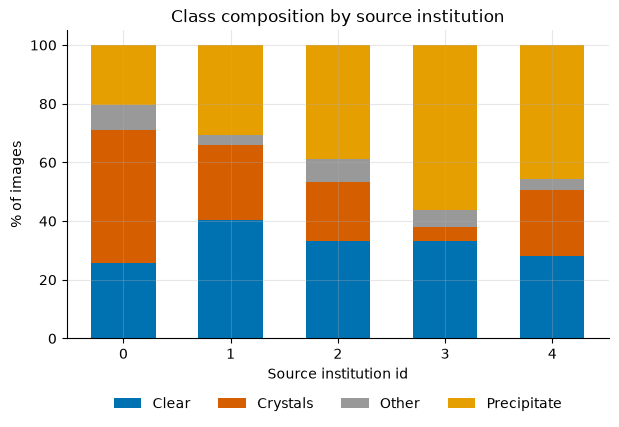

label,Clear,Crystals,Other,Precipitate
source,,,,
0,25.9,45.3,8.4,20.5
1,40.3,25.5,3.5,30.7
2,33.1,20.0,8.0,38.8
3,33.2,4.9,5.6,56.3
4,28.0,22.7,3.6,45.8


In [7]:
comp = pd.crosstab(analysis_df["source"], analysis_df["label"], normalize="index")[CLASS_ORDER] * 100

fig, ax = plt.subplots(figsize=(7, 4))
bottom = np.zeros(len(comp))
for cls in CLASS_ORDER:
    ax.bar(comp.index.astype(str), comp[cls], bottom=bottom, color=CLASS_COLORS[cls], label=cls, width=0.6)
    bottom += comp[cls].values
ax.set_xlabel("Source institution id")
ax.set_ylabel("% of images")
ax.set_title("Class composition by source institution")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
fig.savefig(FIGURES_DIR / "q1_class_composition_by_source.png", dpi=150, bbox_inches="tight")
plt.show()

comp.round(1)

## Image size and quality checks

In [8]:
sample_df = analysis_df.sample(n=min(500, len(analysis_df)), random_state=42)

dims = []
for p in sample_df["path"]:
    with Image.open(DATA_DIR / p) as img:
        dims.append(img.size)  # (width, height)

dims_df = pd.DataFrame(dims, columns=["width", "height"])
print(f"sampled {len(dims_df)} images (seed=42)")
print(dims_df.describe())
print("\nmost common (width, height) pairs:")
dims_df.value_counts().head(10)

sampled 500 images (seed=42)
             width      height
count   500.000000   500.00000
mean   1218.672000   940.16000
std     322.069704   265.52346
min     632.000000   504.00000
25%    1224.000000   960.00000
50%    1280.000000   960.00000
75%    1280.000000   960.00000
max    2448.000000  2048.00000

most common (width, height) pairs:


width  height
1280   960       342
632    504        72
1224   1024       69
2448   2048       17
Name: count, dtype: int64

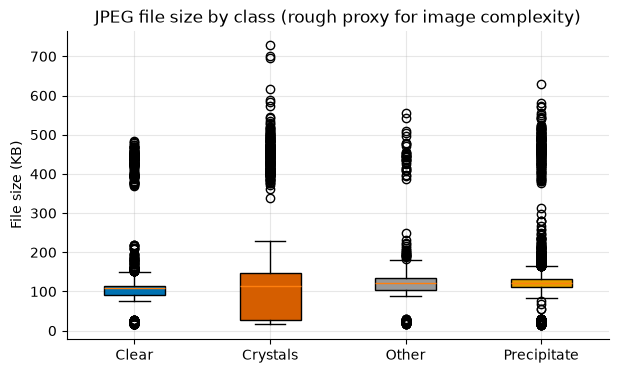

In [9]:
manifest = pd.read_csv(DATA_DIR / "raw" / "manifest.csv")
analysis_with_size = analysis_df.merge(manifest[["image_id", "n_bytes"]], on="image_id", how="left")

fig, ax = plt.subplots(figsize=(7, 4))
data_by_class = [analysis_with_size.loc[analysis_with_size["label"] == c, "n_bytes"] / 1024 for c in CLASS_ORDER]
bp = ax.boxplot(data_by_class, tick_labels=CLASS_ORDER, patch_artist=True)
for patch, cls in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
ax.set_ylabel("File size (KB)")
ax.set_title("JPEG file size by class (rough proxy for image complexity)")
fig.savefig(FIGURES_DIR / "q1_filesize_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

## Leakage checks

`scripts/make_splits.py` groups images from the same physical drop (plate+well, or a detected
near-duplicate) so no group's images cross a split boundary - see that script's docstring for
the full three-tier method. Re-verifying and summarising here for the report.

In [10]:
def group_tier(key: str) -> str:
    if key.startswith("single_"):
        return "no filename/hash group (singleton)"
    if key.startswith("hashdup_"):
        return "near-duplicate hash group (no filename info)"
    if key.startswith("plate"):
        return "plate+well filename pattern"
    if key.startswith("X"):
        return "X-pattern filename (plate+well+timestamp)"
    return "hash+well filename pattern"

analysis_df["group_tier"] = analysis_df["group_key"].apply(group_tier)
print(analysis_df["group_tier"].value_counts())

group_sizes = analysis_df.groupby("group_key").size()
print("\ngroup size distribution:")
print(group_sizes.value_counts().sort_index())

spans = analysis_df.groupby("group_key")["split"].nunique()
assert (spans == 1).all(), "a group spans multiple splits - leakage!"
print("\nconfirmed: no group spans more than one split")

group_tier
plate+well filename pattern                     7632
X-pattern filename (plate+well+timestamp)       2025
hash+well filename pattern                      1818
near-duplicate hash group (no filename info)     440
no filename/hash group (singleton)               399
Name: count, dtype: int64

group size distribution:
1     11247
2       339
3        22
4         8
5         7
6         5
7         2
12        2
14        2
16        1
20        1
23        1
25        2
51        1
Name: count, dtype: int64

confirmed: no group spans more than one split


In [11]:
big = group_sizes[group_sizes >= 12].index
print(analysis_df[analysis_df["group_key"].isin(big)]
      .groupby("group_key")
      .agg(n=("label", "size"), tier=("group_tier", "first"),
           labels=("label", lambda s: s.value_counts().to_dict())))

                                                     n  \
group_key                                                
hashdup_000000000001110000111100001111000011110...  25   
hashdup_000000000001110000111100001111100011110...  14   
hashdup_000000000001110000111100001111100011111...  16   
hashdup_000000000001110000111100001111100011111...  51   
hashdup_000000000001110000111110001111100011111...  25   
hashdup_000010000001110000111110001111100011111...  14   
hashdup_000110000011110001111110011111100111111...  12   
hashdup_000110000011110001111110011111100111111...  20   
hashdup_000110000011110001111110011111100111111...  23   
hashdup_001111000111111001111110011111100111111...  12   

                                                                                            tier  \
group_key                                                                                          
hashdup_000000000001110000111100001111000011110...  near-duplicate hash group (no filename info)   
has

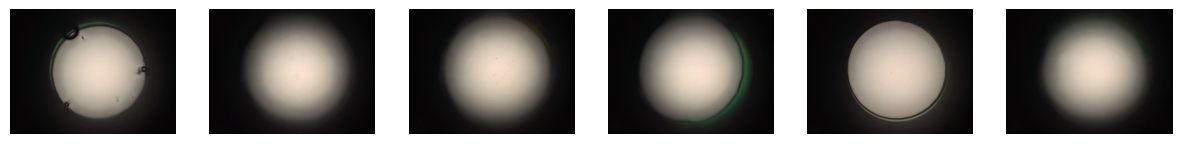

In [12]:
import matplotlib.pyplot as plt
from PIL import Image
key = group_sizes.idxmax()   # the 51-image group
paths = analysis_df.loc[analysis_df["group_key"] == key, "path"].head(6)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, p in zip(axes, paths):
    ax.imshow(Image.open(DATA_DIR / p)); ax.axis("off")
fig.savefig(FIGURES_DIR / "q1_leakage_group_example.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
multi_groups = group_sizes[group_sizes > 1].index
multi_df = analysis_df[analysis_df["group_key"].isin(multi_groups)]
label_nunique = multi_df.groupby("group_key")["label"].nunique()
n_drift = (label_nunique > 1).sum()
print(f"{len(multi_groups)} groups have more than one image")
print(f"{n_drift} of them ({n_drift / len(multi_groups) * 100:.1f}%) show different labels across images "
      "within the same group. See the d-number cross-reference below for what actually explains most "
      "of this (mostly different drops sharing a well, not one drop changing over time). Either way, "
      "the split still keeps the whole group together; each group's majority label was used only to "
      "stratify the split, not as a claim that the group has one true label.")

393 groups have more than one image
61 of them (15.5%) show different labels across images within the same group. See the d-number cross-reference below for what actually explains most of this (mostly different drops sharing a well, not one drop changing over time). Either way, the split still keeps the whole group together; each group's majority label was used only to stratify the split, not as a claim that the group has one true label.


In [14]:
drift_keys = label_nunique[label_nunique > 1].index
print(multi_df[multi_df["group_key"].isin(drift_keys)]
      .groupby("group_key")["label"]
      .agg(lambda s: " / ".join(sorted(s.unique())))
      .value_counts())

label
Clear / Precipitate       30
Other / Precipitate       19
Crystals / Precipitate     4
Clear / Crystals           3
Clear / Other              3
Crystals / Other           2
Name: count, dtype: int64


**Interpretation.** The largest hash groups (up to 51 images) are all single-label and visually
generic - spot-checking the 51-image `Clear` group shows clearly different wells (different bubble
shapes/artifacts), not the same physical drop imaged repeatedly. The coarse average-hash collides
on visually simple images (an empty well is just a bright circle on a dark background), so the
`hashdup_` tier over-groups for simple classes rather than finding true duplicates. This is **safe,
not dangerous**, for the leakage rule - grouping unrelated images together only wastes some split
flexibility, it never lets a true duplicate land on both sides of a split. But it means `hashdup_`
groups should be read as "visually generic, merged conservatively," not literally "same drop."

The label-drift pairs are also informative: `Clear`/`Precipitate` and `Other`/`Precipitate` make up
most of the drift (28 and 20 of 58 drifting groups). The d-number cross-reference below shows most
of this drift is different drops sharing a well rather than one drop changing state over time - see
that section for the full breakdown.


00k9_H5  (2 images)
                       filename       label  time split
00k9_H5_CrossPolarization_3.jpg Precipitate     3 train
00k9_H5_CrossPolarization_9.jpg    Crystals     9 train


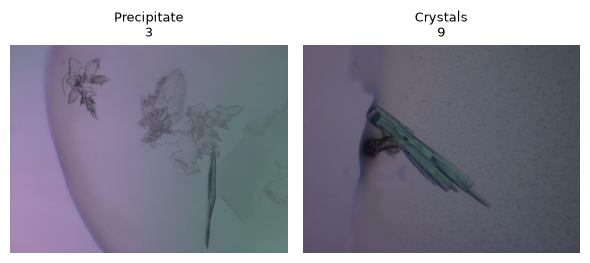


plate1696well2  (2 images)
                                                                 filename       label  time split
folderID696_plateID1696_batchID7042_wellNum2_profileID1_d1_r112561_ef.jpg    Crystals     1 train
folderID696_plateID1696_batchID6997_wellNum2_profileID1_d2_r112562_ef.jpg Precipitate     2 train


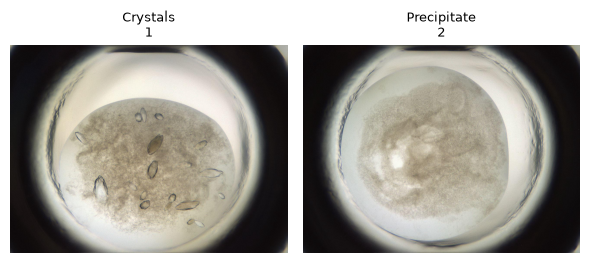


plate1718well83  (2 images)
                                                                  filename       label  time split
folderID718_plateID1718_batchID7137_wellNum83_profileID1_d2_r114021_ef.jpg    Crystals     2 train
folderID718_plateID1718_batchID7137_wellNum83_profileID1_d3_r114022_ef.jpg Precipitate     3 train


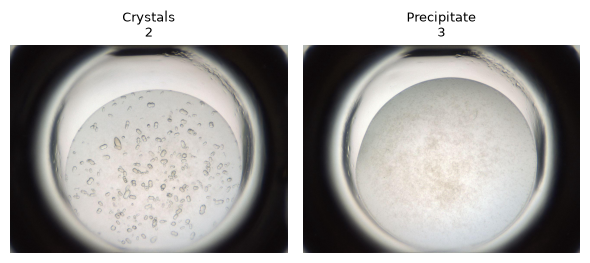


plate2423well25  (2 images)
                                                                   filename       label  time split
folderID423_plateID2423_batchID11664_wellNum25_profileID1_d1_r180080_ef.jpg    Crystals     1   val
folderID423_plateID2423_batchID11664_wellNum25_profileID1_d2_r180081_ef.jpg Precipitate     2   val


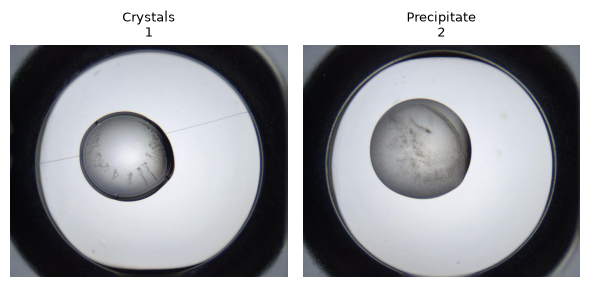

In [15]:
import re
import matplotlib.pyplot as plt
from PIL import Image

pair_keys = (multi_df[multi_df["group_key"].isin(drift_keys)]
             .groupby("group_key")["label"]
             .agg(lambda s: " / ".join(sorted(s.unique()))))
cp_keys = pair_keys[pair_keys == "Crystals / Precipitate"].index

def time_key(fn: str):
    """The _d<N>_ imaging-round marker if present, else a date like 20040928(+time), else
    a trailing frame number. _d<N>_ comes first since it's what plate+well filenames use."""
    m = re.search(r"_d(\d+)_", fn)
    if m:
        return int(m.group(1))
    m = re.search(r"(20\d{6})(\d{4})?", fn)
    if m:
        return m.group(0)
    m = re.search(r"_(\d+)\.\w+$", fn)
    return int(m.group(1)) if m else None

for key in cp_keys:
    g = analysis_df[analysis_df["group_key"] == key].copy()
    g["time"] = g["filename"].apply(time_key)
    g = g.sort_values(["time", "filename"], na_position="last")
    print(f"\n{key}  ({len(g)} images)")
    print(g[["filename", "label", "time", "split"]].to_string(index=False))

    fig, axes = plt.subplots(1, len(g), figsize=(3 * len(g), 3), squeeze=False)
    for ax, (_, r) in zip(axes[0], g.iterrows()):
        ax.imshow(Image.open(DATA_DIR / r["path"]))
        ax.set_title(f"{r['label']}\n{r['time']}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / f"q1_crystals_precip_{key}.png", dpi=150, bbox_inches="tight")
    plt.show()

**Conclusion across all 4 groups**

| Group | Same drop? | Timing | Explanation |
|---|---|---|---|
| 00k9_H5 | Likely | Round 3 → 9 | Possible growth over time, plus an ambiguous early label |
| plate1696well2 | No (d2, d1) | Different batches | Different drops |
| plate1718well83 | No (d2, d3) | Same session | Different drops |
| plate2423well25 | No (d1, d2) | Same session | Different drops |

**Crystals ↔ Precipitate transitions, time-ordered.** For the 4 plate+well groups where images
within the same well carry both `Crystals` and `Precipitate` labels, order the images
chronologically and look at them side by side - a direct visual check of the kinetic-process
explanation above, saved as `docs/figures/q1_crystals_precip_<group_key>.png`.

Ordering note: most of these filenames carry their imaging round as `_d<N>_` (matching the
d-number analysis below), not a date or trailing frame number, so `time_key` checks for `_d<N>_`
first - an earlier version of this check missed that pattern and silently fell back to plain
filename-string order, which does not reliably sort d1 before d2.

In [16]:
pw = analysis_df[analysis_df["group_key"].str.startswith("plate")].copy()
pw["drop"] = pw["filename"].str.extract(r"_d(\d+)_", expand=False)
print(pw["drop"].value_counts(dropna=False))
print((pw.groupby("group_key")["drop"].nunique() > 1).sum(),
      "plate+well groups contain more than one d-number")

drop
1    5125
2    2262
3     245
Name: count, dtype: int64
164 plate+well groups contain more than one d-number


In [17]:
n_drop = pw.groupby("group_key")["drop"].nunique()
mixed = label_nunique[label_nunique > 1].index
mixed_pw = [k for k in mixed if k in n_drop.index]
multi_drop = sum(n_drop[k] > 1 for k in mixed_pw)
print(f"{len(mixed_pw)} of 58 mixed-label groups are plate+well groups; "
      f"{multi_drop} of them contain more than one drop")

58 of 58 mixed-label groups are plate+well groups; 47 of them contain more than one drop


**Of the 58 mixed-label groups, 44 (76%) are explained by different drops in the same well.**

| Mixed-label groups | Count | Main explanation |
|---|---|---|
| Plate+well groups, more than one drop | 44 | **Different drops** in the same well |
| Plate+well groups, a single drop | 11 | Same drop, different labels: change over time or scorer disagreement |
| Code+well groups (e.g. `00k9_H5`) | 3 | Same well across imaging rounds: change over time or scorer disagreement |
| **Total** | **58** | |

**What this means**

- Most label “drift” isn’t drift at all. It’s two different drops sharing a well. Your earlier “kinetic process” explanation applies to at most 14 groups (24%). For the 11 single-drop groups you could check whether the batchID differs; if it does, the images are probably from different imaging sessions, which supports change over time.
- The leakage control still holds. All 58 groups stay inside one split either way.
Fix the wording in your notebook cell. It currently says the mixed labels are “consistent with crystallisation being a kinetic process”. Change it to match these results.

**Of the 413 groups with more than one image, 58 (14.0%) contain more than one label. Most of these (44, 76%) are plate+well groups holding images of different drops (drop numbers d1–d3), so the labels describe different drops rather than one drop changing. The remaining 14 groups hold a single drop or well series: differences there are consistent with change between imaging rounds or with disagreement between scorers. Grouping by well keeps all of them inside one split.**

## Leakage check: plate and well in X-format filenames

In [18]:
# Step 1: check the structure is real
# My reading is: X + 10-digit plate + 3-digit well + 12-digit timestamp. That’s a guess, so test it first:

import pandas as pd

x = splits[splits["filename"].str.startswith("X")].copy()
x["match"] = x["filename"].str.match(r"^X\d{25}\.png$")
print(len(x), "X-filenames;", x["match"].sum(), "fit the X + 25 digits pattern")

x = x[x["match"]].copy()
x["plate"] = x["filename"].str[1:11]
x["well"]  = x["filename"].str[11:14].astype(int)
x["ts"]    = pd.to_datetime(x["filename"].str[14:26], format="%Y%m%d%H%M", errors="coerce")

print("valid timestamps:", x["ts"].notna().mean().round(3))
print("timestamp range:", x["ts"].min(), "to", x["ts"].max())
print("well numbers:", x["well"].min(), "to", x["well"].max())
print("distinct plates:", x["plate"].nunique())

2359 X-filenames; 2359 fit the X + 25 digits pattern
valid timestamps: 1.0
timestamp range: 2004-09-10 12:51:00 to 2005-09-07 16:21:00
well numbers: 0 to 999
distinct plates: 410


In [19]:
# Why test a 4-digit well number?
# The 10 + 3 reading (10-digit plate + 3-digit well) gave wells 0 to 999,
# the full range of three digits, which doesn't fit cleanly:
#   - wells normally start at 1, not 0
#   - Hauptman-Woodward uses 1,536-well plates, so well numbers up to 1536
#     need four digits
# So the split may really be a 9-digit plate + 4-digit well. Test that here.

w4 = x["filename"].str[10:14].astype(int)
print("4-digit reading: wells", w4.min(), "to", w4.max(),
      "| plates", x["filename"].str[1:10].nunique())

#   X + 9-digit plate + 4-digit well + 12-digit timestamp (YYYYMMDDhhmm) + .png

4-digit reading: wells 2 to 1536 | plates 242


In [20]:
# Step 2: look for leakage
# Group X-format images by plate + well (9-digit plate + 4-digit well) and check
# whether any well's images were placed in more than one split.
# Uses all splits (train, val, test) but reads only filenames and split names.

x["plate"] = x["filename"].str[1:10]
x["well"]  = x["filename"].str[10:14].astype(int)
x["plate_well"] = "X" + x["plate"] + "_w" + x["well"].astype(str)

reps = x.groupby("plate_well").agg(n=("filename", "size"),
                                   n_splits=("split", "nunique"),
                                   n_labels=("label", "nunique"))
multi = reps[reps["n"] > 1]
n_leaking = (multi["n_splits"] > 1).sum()
print(len(multi), "plate+well keys have more than one image,",
      multi["n"].sum(), "images in total")
print(n_leaking, "of them span more than one split  <- leakage")

assert n_leaking == 0, (
    f"{n_leaking} X-pattern well(s) still span more than one split - the v2 split regeneration "
    "did not fix this; do not proceed to modelling until this is 0."
)
print("confirmed: no X-pattern well spans more than one split")

2 plate+well keys have more than one image, 4 images in total
0 of them span more than one split  <- leakage
confirmed: no X-pattern well spans more than one split


In [21]:
leak_keys = multi[multi["n_splits"] > 1].index
print(x[x["plate_well"].isin(leak_keys)][["filename", "label", "split", "ts"]])

Empty DataFrame
Columns: [filename, label, split, ts]
Index: []



X000004664_w859  (2 images)
                      filename    label split                  ts
X0000046640859200502031501.png Crystals  test 2005-02-03 15:01:00
X0000046640859200502241412.png Crystals  test 2005-02-24 14:12:00


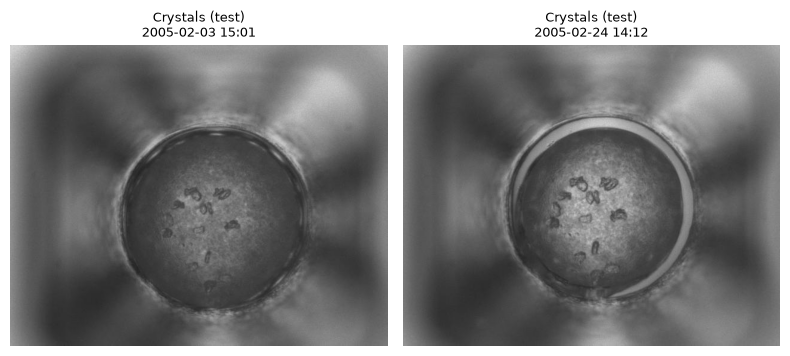


X000005130_w1048  (2 images)
                      filename    label split                  ts
X0000051301048200506241749.png Crystals train 2005-06-24 17:49:00
X0000051301048200507152355.png Crystals train 2005-07-15 23:55:00


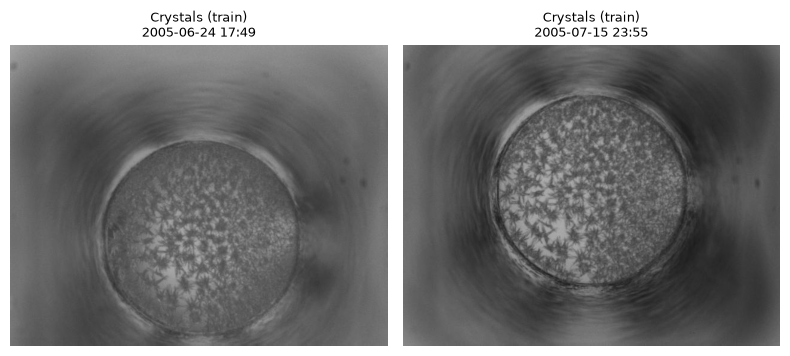

In [22]:
import matplotlib.pyplot as plt
from PIL import Image

for key in multi.index:
    g = x[x["plate_well"] == key].sort_values("ts")
    print(f"\n{key}  ({len(g)} images)")
    print(g[["filename", "label", "split", "ts"]].to_string(index=False))

    fig, axes = plt.subplots(1, len(g), figsize=(4 * len(g), 3.5), squeeze=False)
    for ax, (_, r) in zip(axes[0], g.iterrows()):
        ax.imshow(Image.open(DATA_DIR / r["path"]))
        ax.set_title(f"{r['label']} ({r['split']})\n{r['ts']:%Y-%m-%d %H:%M}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / f"q1_xwell_leak_{key}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Findings: X-format filename leakage check

**Filename structure confirmed.** All 2,359 X-format filenames (Hauptman-Woodward images) follow one pattern:

`X` + 9-digit plate + 4-digit well + 12-digit timestamp (`YYYYMMDDhhmm`) + `.png`

- 100% of timestamps are valid dates, from September 2004 to September 2005.
- Well numbers run from 2 to 1536, matching 1,536-well plates. An earlier 10 + 3 digit reading gave wells 0–999, which did not fit.
- 242 distinct plates.

**Leakage found.** Grouping these images by plate + well:

- 2 wells have more than one image (4 images in total).
- 1 well crosses a split boundary.

| Well | Images | Dates | Splits | Same drop? | Leak? |
|---|---|---|---|---|---|
| X000004664_w859 | 2 (Crystals) | 3 Feb → 24 Feb 2005 | train, train | Yes: same crystal cluster | No |
| X000005130_w1048 | 2 (Crystals) | 24 Jun → 15 Jul 2005 | **test, val** | Yes: same star-shaped crystal pattern | **Yes** |

**Why the original grouping missed it.** These filenames matched neither existing filename pattern, so the images fell back to the average hash. Lighting and the ring around the drop changed between imaging sessions, so the two images of well w1048 produced different 8×8 hashes and each became a one-image group. An exact hash misses near-duplicates; filename information is more reliable.

**Impact.** 2 of 14,367 images (0.01%). Small, but a near-identical copy of a test image in the validation set would make thresholds and model choices, and so the final test score, slightly optimistic.

**Action.** Before any modelling:

1. Keep the old split as `data/splits_v1.csv`.
2. Add a third filename pattern to `make_splits.py`: `^X(\d{9})(\d{4})\d{12}\.png$` → `X{plate}_w{well}`.
3. Regenerate the split with `--force`.
4. Rerun this check (expected: 0 wells span more than one split) and rerun the EDA cells, because split counts change.

Test-isolation note: this check read test filenames and split names, and the two images of well w1048 were viewed once to confirm the leak. No test image was used for any modelling decision.

## v1 vs v2 split comparison

`data/splits_v1.csv` is the split before the X-pattern fix, kept specifically for this
comparison (never read anywhere else in the pipeline). Quantify what actually changed, and show
the leak example's exact before/after split assignment side by side - not just "now consistent,"
but assigned to a genuinely different split than either of the two it was in before.

In [23]:
v1 = pd.read_csv(DATA_DIR / "splits_v1.csv")

cmp = v1[["image_id", "group_key", "split"]].merge(
    splits[["image_id", "group_key", "split"]],
    on="image_id", suffixes=("_v1", "_v2"),
)

n_changed = (cmp["split_v1"] != cmp["split_v2"]).sum()
print(f"{n_changed} of {len(cmp)} images changed split assignment between v1 and v2 "
      f"({n_changed / len(cmp) * 100:.2f}%)")
print("\nsplit transitions (v1 -> v2) for images that changed:")
print(pd.crosstab(cmp.loc[cmp["split_v1"] != cmp["split_v2"], "split_v1"],
                   cmp.loc[cmp["split_v1"] != cmp["split_v2"], "split_v2"]))

print("\ngroup_key also changed for these counts of images (filename now matches PATTERN_X "
      "instead of falling back to single_/hashdup_):")
print((cmp["group_key_v1"] != cmp["group_key_v2"]).sum())

6328 of 14367 images changed split assignment between v1 and v2 (44.05%)

split transitions (v1 -> v2) for images that changed:
split_v2  test  train   val
split_v1                   
test         0   1452   270
train     1424      0  1456
val        298   1428     0

group_key also changed for these counts of images (filename now matches PATTERN_X instead of falling back to single_/hashdup_):
2359


In [24]:
# The specific leak, before and after. Note the fix isn't just "now in the same split" -
# both images moved to a split neither was in before (test/val -> train/train).
leak_filenames = ["X0000051301048200506241749.png", "X0000051301048200507152355.png"]
leak_cmp = v1[v1["filename"].isin(leak_filenames)][["filename", "label", "group_key", "split"]].merge(
    splits[splits["filename"].isin(leak_filenames)][["filename", "group_key", "split"]],
    on="filename", suffixes=("_v1", "_v2"),
)
leak_cmp

,filename,label,group_key_v1,split_v1,group_key_v2,split_v2
0,X0000051301048200506241749.png,Crystals,single_467026,test,X000005130_w1048,train
1,X0000051301048200507152355.png,Crystals,single_467027,val,X000005130_w1048,train


## Final leakage check: all tiers, all three splits

`scripts/make_splits.py` asserts no group spans a split at build time, over the full manifest
(including test), and that assertion passed. Everything above independently re-checks this in
the notebook too, but only for train+val (`ef28ed5f`, by design - this notebook avoids touching
test for general exploration) or only for the X-pattern tier against test (`265ad29a`, a
deliberate, documented exception made specifically because that's where the known leak was).

So the plate+well, hash+well and hashdup tiers have never been independently re-checked against
test *in this notebook* - only the script's internal check covers them. Close that gap here, the
same way the X-pattern check was done: read `group_key` and `split` (not image content) across
all three splits, for every tier, and assert.

Test-isolation note: like the X-pattern check above, this reads test's `group_key`/`split`
columns only, to verify the split boundary itself - no test image content is used, and nothing
here informs any modelling decision.

In [25]:
full_tier = splits["group_key"].apply(group_tier)
full_spans = splits.groupby("group_key")["split"].nunique()
n_leaking_groups = (full_spans > 1).sum()

leaking_keys = full_spans[full_spans > 1].index
by_tier = full_tier[splits["group_key"].isin(leaking_keys)].value_counts()
print("leaking groups by tier:")
print(by_tier if len(by_tier) else "none")

assert n_leaking_groups == 0, (
    f"{n_leaking_groups} group(s) span more than one split across the full dataset (incl. test) "
    "- leakage! Do not proceed to modelling."
)
print(f"\nconfirmed: all {splits['group_key'].nunique()} groups, across every tier "
      "(plate+well, hash+well, X-pattern, hashdup, singleton) and all three splits "
      "(train, val, test), stay within one split.")

leaking groups by tier:
none

confirmed: all 13578 groups, across every tier (plate+well, hash+well, X-pattern, hashdup, singleton) and all three splits (train, val, test), stay within one split.


**Limitation: relationships beyond the well.** Everything above protects against the same
physical drop (same plate+well) appearing in more than one split. It does not, and cannot,
protect against the same protein or the same screening conditions being run on a *different*
plate - a common practice in crystallisation screening (replicate plates, repeat attempts,
broader condition screens). Two images from different plates could still share protein-specific
visual characteristics without being the same physical drop. MARCO's metadata carries no protein
ID, batch ID, or experiment ID linking plates together, and nothing in the filenames identifies
this either, so this risk cannot be detected or controlled for with the available metadata. This
is a residual limitation of the dataset itself, not a gap in the grouping method above.

## FP/FN consequences and metric justification

A false negative (a missed Crystals image) can lose a hit from scarce, expensive protein - the
sample may not be recoverable. A false positive costs a crystallographer a few minutes of manual
inspection. These costs are highly asymmetric, and Crystals is the minority class, so accuracy is
misleading as a headline metric - a classifier can score well on accuracy while being useless for
the actual decision. A concrete illustration:

In [26]:
majority_class = analysis_df["label"].value_counts().idxmax()
majority_acc = (analysis_df["label"] == majority_class).mean() * 100

print(f"Always predicting '{majority_class}': accuracy = {majority_acc:.1f}%, "
      f"but Crystals recall = 0% - every crystal hit would be missed, despite a "
      f"seemingly OK accuracy score.")

Always predicting 'Precipitate': accuracy = 47.9%, but Crystals recall = 0% - every crystal hit would be missed, despite a seemingly OK accuracy score.


**Primary metric:** recall on Crystals at a fixed minimum precision, **`P_MIN = 0.30`**, with
PR-AUC for Crystals as a supporting metric. Set 2026-10-28 from the classical baseline's
validation PR curve (`baseline_lgbm_022` in `experiments/log.csv`) - see
`docs/primary_metric.md` for the full reasoning (base rate ~12.4%, cost asymmetry favouring
recall). At `P_MIN = 0.30`, validation recall on Crystals is ~85%. This value is now fixed for
every model family (classical baseline, every ANN variant, GenAI evaluation).

## Three findings that constrain modelling

1. **Crystals is a real minority class (~12% of train+val)**, and the cost of missing one is far
   higher than a false alarm. This rules out accuracy as the headline metric and means the loss
   function/sampling strategy needs to account for the imbalance directly (e.g. class weighting),
   not rely on the model discovering it unaided.
2. **Class mix varies sharply by source institution.** Source 3 (62% of all data) has only 4.8%
   Crystals, while source 0 has 45.1% Crystals - a 9x swing. Since one institution dominates the
   pool, a model could end up implicitly tuned to that institution's imaging style and
   under-perform on the others. This directly bears on the web app's stated limitation about
   unseen imagers (Q4) and suggests checking per-source performance during error analysis (Q3),
   not just aggregate metrics.
3. **Image dimensions are not standardised.** A 500-image sample spans 632x504 up to 2448x2048,
   with `1280x960` as the dominant but not universal size (70% of the sample). This constrains
   preprocessing - an explicit, documented resize/aspect-ratio strategy is needed rather than an
   assumption that every image already arrives at a fixed input size.

## Appendix: how group_key is built

`scripts/make_splits.py`'s `build_group_keys()` assigns every image a leakage-grouping key by
trying three filename patterns in order (first match wins: plate+well, hash+well, X-pattern),
falling through to `assign_hash_groups()`'s average-hash fallback (with its own same-label check)
only when none of the three match. See the Leakage checks section above for the resulting counts
and findings; this is the underlying decision logic.

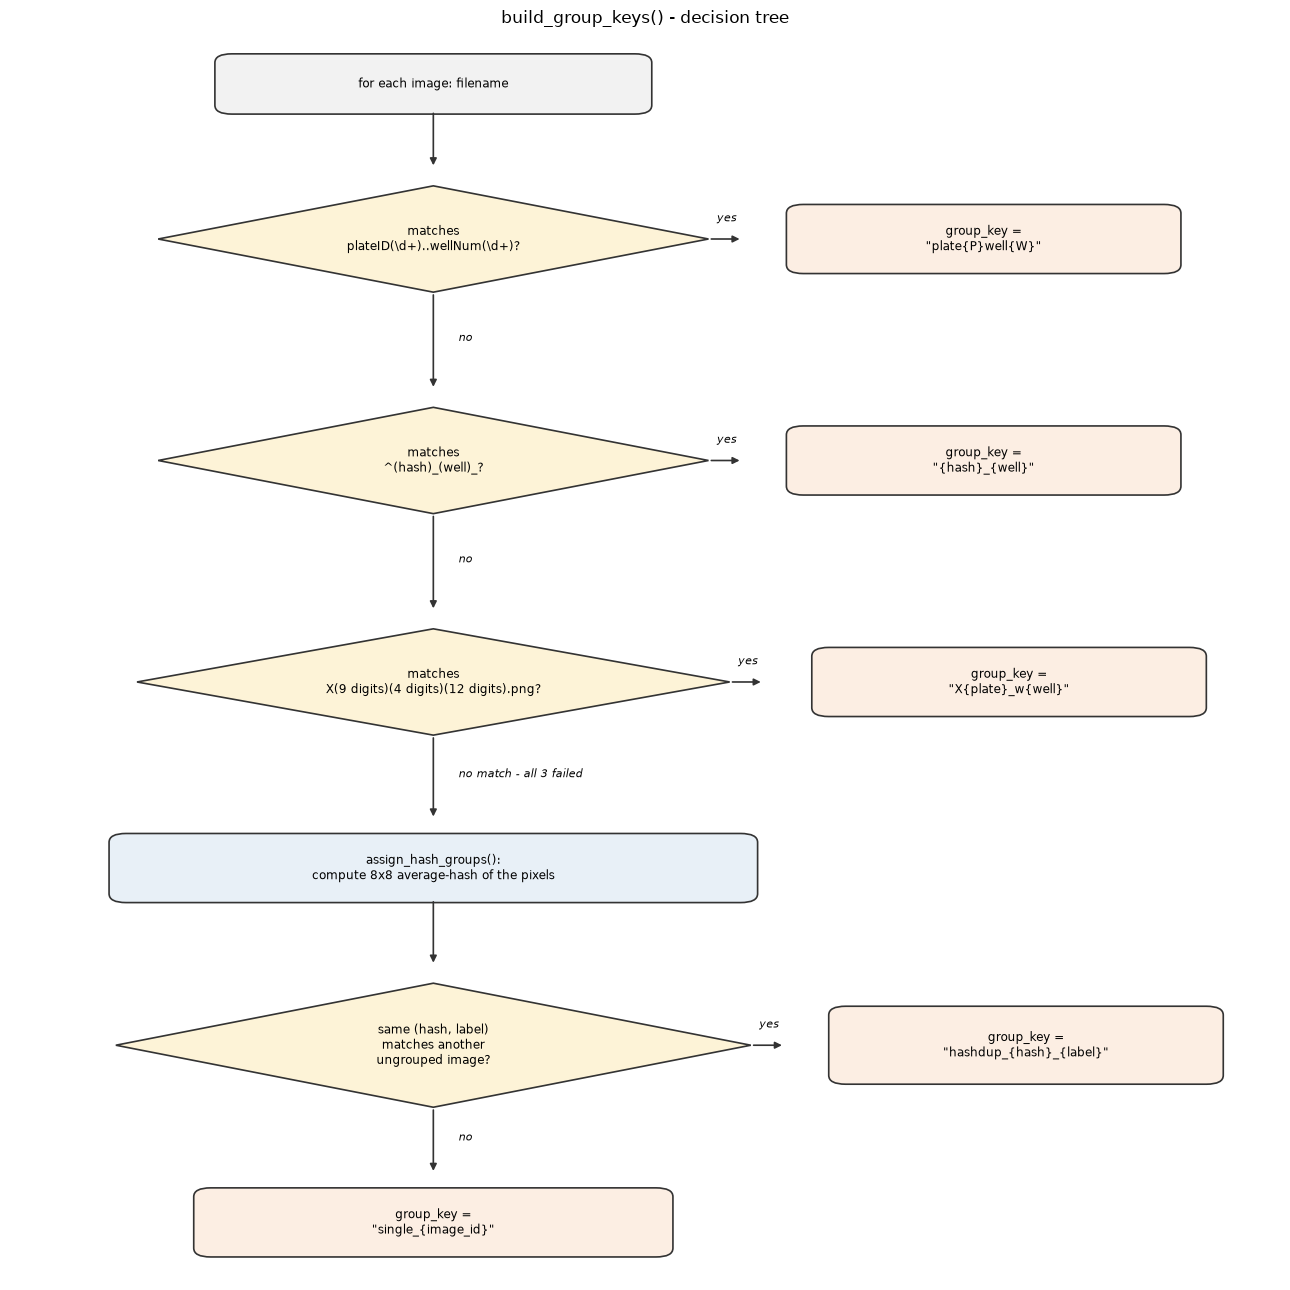

In [27]:
from matplotlib.patches import FancyBboxPatch, Polygon

def flow_box(ax, cx, cy, w, h, text, facecolor="#F2F2F2", fontsize=8.5):
    box = FancyBboxPatch((cx - w / 2, cy - h / 2), w, h,
                          boxstyle="round,pad=0.08,rounding_size=0.2",
                          linewidth=1.2, edgecolor="#333333", facecolor=facecolor)
    ax.add_patch(box)
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fontsize)

def flow_diamond(ax, cx, cy, w, h, text, facecolor="#FDF3D7", fontsize=8.5):
    pts = [(cx, cy + h / 2), (cx + w / 2, cy), (cx, cy - h / 2), (cx - w / 2, cy)]
    ax.add_patch(Polygon(pts, closed=True, linewidth=1.2, edgecolor="#333333", facecolor=facecolor))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fontsize)

def flow_arrow(ax, p_from, p_to):
    ax.annotate("", xy=p_to, xytext=p_from, arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.2))

fig, ax = plt.subplots(figsize=(13, 13))
ax.set_xlim(0, 15)
ax.set_ylim(0, 28)
ax.axis("off")
ax.set_title("build_group_keys() - decision tree", fontsize=12, pad=12)

flow_box(ax, 5, 27, 5, 1.2, "for each image: filename")
flow_arrow(ax, (5, 26.4), (5, 25.1))

# --- filename_group_key(): 3 pattern checks, first match wins ---
flow_diamond(ax, 5, 23.5, 6.5, 2.4, "matches\nplateID(\\d+)..wellNum(\\d+)?")
flow_arrow(ax, (8.25, 23.5), (8.65, 23.5))
ax.text(8.35, 23.9, "yes", fontsize=8, style="italic")
flow_box(ax, 11.5, 23.5, 4.5, 1.4, 'group_key =\n"plate{P}well{W}"', facecolor="#FCEEE3", fontsize=8.5)
flow_arrow(ax, (5, 22.3), (5, 20.1))
ax.text(5.3, 21.2, "no", fontsize=8, style="italic")

flow_diamond(ax, 5, 18.5, 6.5, 2.4, 'matches\n^(hash)_(well)_?')
flow_arrow(ax, (8.25, 18.5), (8.65, 18.5))
ax.text(8.35, 18.9, "yes", fontsize=8, style="italic")
flow_box(ax, 11.5, 18.5, 4.5, 1.4, 'group_key =\n"{hash}_{well}"', facecolor="#FCEEE3", fontsize=8.5)
flow_arrow(ax, (5, 17.3), (5, 15.1))
ax.text(5.3, 16.2, "no", fontsize=8, style="italic")

flow_diamond(ax, 5, 13.5, 7.0, 2.4, "matches\nX(9 digits)(4 digits)(12 digits).png?")
flow_arrow(ax, (8.5, 13.5), (8.9, 13.5))
ax.text(8.6, 13.9, "yes", fontsize=8, style="italic")
flow_box(ax, 11.8, 13.5, 4.5, 1.4, 'group_key =\n"X{plate}_w{well}"', facecolor="#FCEEE3", fontsize=8.5)
flow_arrow(ax, (5, 12.3), (5, 10.4))
ax.text(5.3, 11.35, "no match - all 3 failed", fontsize=8, style="italic")

# --- assign_hash_groups() fallback ---
flow_box(ax, 5, 9.3, 7.5, 1.4, "assign_hash_groups():\ncompute 8x8 average-hash of the pixels",
         facecolor="#E8F0F7")
flow_arrow(ax, (5, 8.6), (5, 7.1))

flow_diamond(ax, 5, 5.3, 7.5, 2.8, "same (hash, label)\nmatches another\nungrouped image?")
flow_arrow(ax, (8.75, 5.3), (9.15, 5.3))
ax.text(8.85, 5.7, "yes", fontsize=8, style="italic")
flow_box(ax, 12.0, 5.3, 4.5, 1.6, 'group_key =\n"hashdup_{hash}_{label}"', facecolor="#FCEEE3", fontsize=8.5)

flow_arrow(ax, (5, 3.9), (5, 2.4))
ax.text(5.3, 3.15, "no", fontsize=8, style="italic")
flow_box(ax, 5, 1.3, 5.5, 1.4, 'group_key =\n"single_{image_id}"', facecolor="#FCEEE3", fontsize=8.5)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "q1_build_group_keys_decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()